In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from imblearn.over_sampling import SMOTE

In [39]:
filepath = "/content/drive/MyDrive/ICT_AIML_DATAS/DataFrame/adult_dataset.csv"

In [40]:
df = pd.read_csv(filepath)

df.shape

(48842, 15)

In [41]:
df.head()

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39.0,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40.0,NaN,<=50K
1,50.0,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13.0,United-States,<=50K
2,38.0,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40.0,United-States,<=50K
3,53.0,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40.0,United-States,<=50K
4,28.0,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40.0,Cuba,<=50K


In [42]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             46400 non-null  float64
 1   workclass       45480 non-null  object 
 2   fnlwgt          48842 non-null  int64  
 3   education       48842 non-null  object 
 4   education-num   48842 non-null  int64  
 5   marital-status  48842 non-null  object 
 6   occupation      45485 non-null  object 
 7   relationship    48842 non-null  object 
 8   race            48842 non-null  object 
 9   sex             48842 non-null  object 
 10  capital-gain    48842 non-null  int64  
 11  capital-loss    48842 non-null  int64  
 12  hours-per-week  46400 non-null  float64
 13  native-country  46137 non-null  object 
 14  income          48842 non-null  object 
dtypes: float64(2), int64(4), object(9)
memory usage: 5.6+ MB


In [43]:
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week
count,46400.000000,4.884200e+04,48842.000000,48842.000000,48842.000000,46400.000000
mean,38.679116,1.896641e+05,10.078089,1079.067626,87.502314,40.448599
std,13.952954,1.056040e+05,2.570973,7452.019058,403.004552,12.646992
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.175505e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.781445e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.376420e+05,12.000000,0.000000,0.000000,45.000000
max,255.000000,1.490400e+06,16.000000,99999.000000,4356.000000,250.000000


In [44]:
df.duplicated().sum()

np.int64(16)

In [45]:
df.isna().sum()

,0
age,2442
workclass,3362
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,3357
relationship,0
race,0
sex,0


In [46]:
# checking  class imbalance

df["income"].value_counts()

,count
income,
<=50K,24720
<=50K.,12435
>50K,7841
>50K.,3846


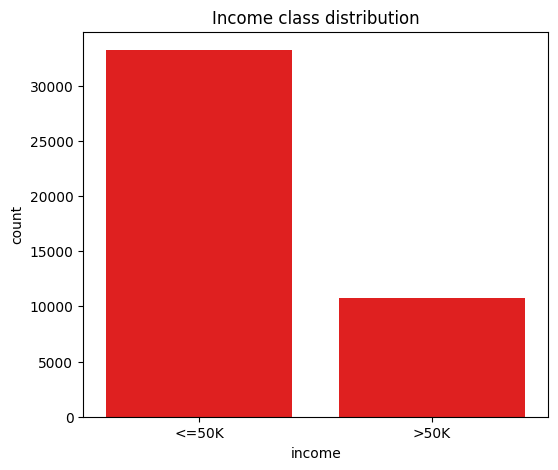

In [73]:
# Target distribution plot for checking class imbalance visually

plt.figure(figsize=(6, 5))
sns.countplot(df, x="income", color ="red")
plt.title("Income class distribution")
plt.show()

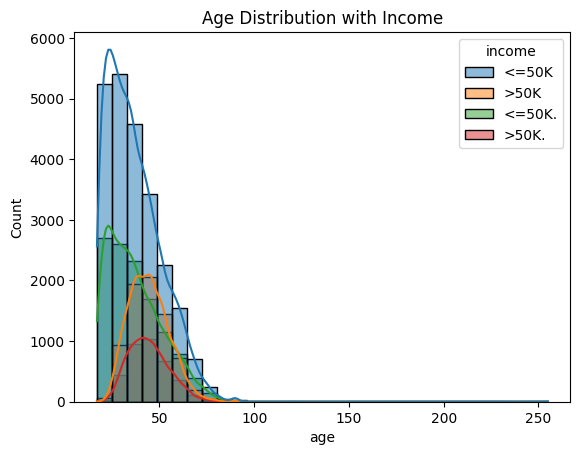

In [48]:
# plotting age distribution with income

sns.histplot(df, x="age", hue="income", bins=30, kde=True)
plt.title("Age Distribution with Income")
plt.show()

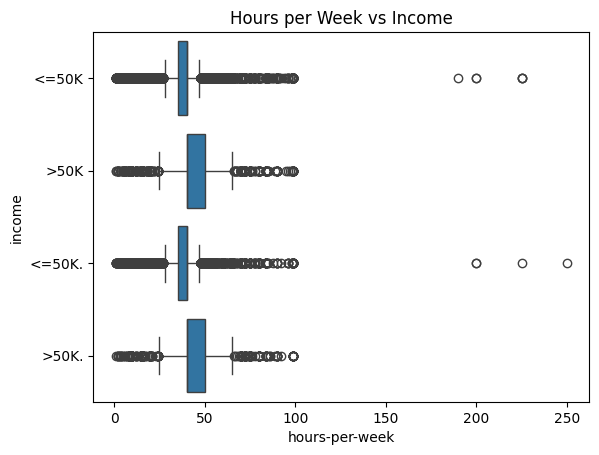

In [49]:
# plotting hours-per-week with income

sns.boxplot(df, x="hours-per-week", y="income")
plt.title("Hours per Week vs Income")
plt.show()

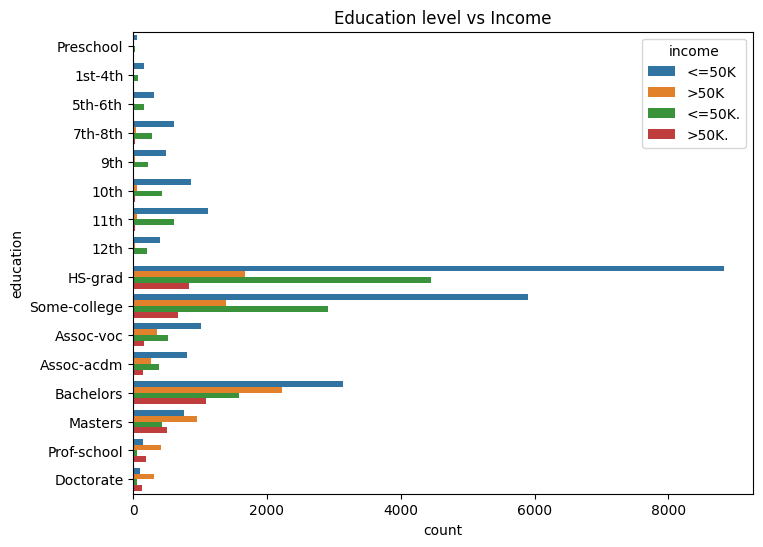

In [50]:
# plotting education level vs income

edu_order = df.groupby("education")["education-num"].mean().sort_values().index

plt.figure(figsize=(8, 6))
sns.countplot(df, y="education", hue="income", order=edu_order)
plt.title("Education level vs Income")
plt.show()

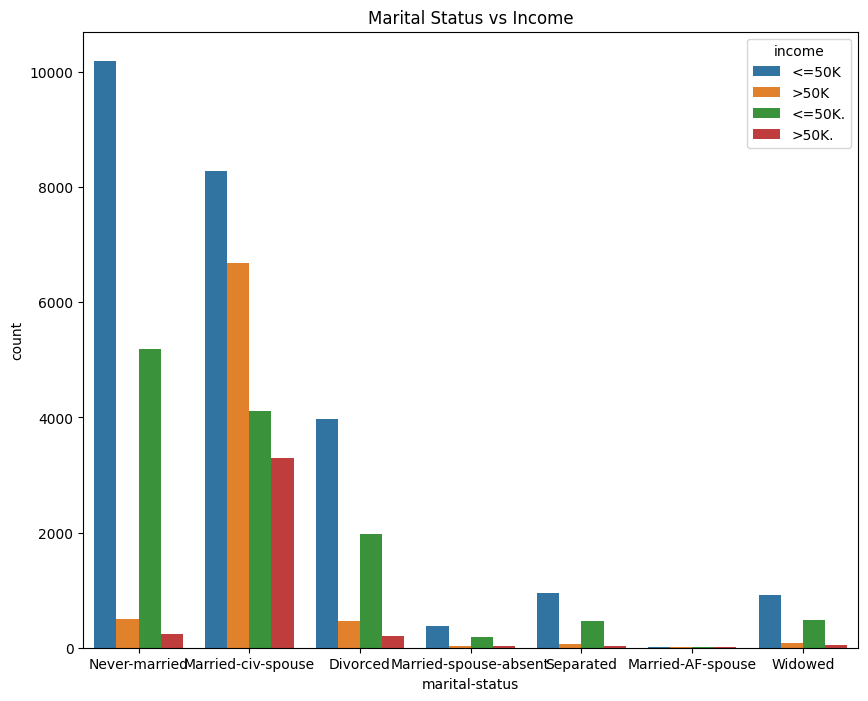

In [51]:
# plotting marital status vs income

plt.figure(figsize=(10, 8))
sns.countplot(df, x="marital-status", hue="income")
plt.title("Marital Status vs Income")
plt.show()

In [52]:
cat_cols_before_split = df.select_dtypes(include=["object", "string"]).columns

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

workclass ---> ['State-gov' 'Self-emp-not-inc' 'Private' 'Federal-gov' nan 'Local-gov'
 '?' 'Self-emp-inc' 'Without-pay' 'Never-worked']
 
education ---> ['Bachelors' 'HS-grad' '11th' 'Masters' '9th' 'Some-college' 'Assoc-acdm'
 'Assoc-voc' '7th-8th' 'Doctorate' 'Prof-school' '5th-6th' '10th'
 '1st-4th' 'Preschool' '12th']
 
marital-status ---> ['Never-married' 'Married-civ-spouse' 'Divorced' 'Married-spouse-absent'
 'Separated' 'Married-AF-spouse' 'Widowed']
 
occupation ---> ['Adm-clerical' 'Exec-managerial' 'Handlers-cleaners' 'Prof-specialty'
 'Other-service' 'Sales' 'Craft-repair' 'Transport-moving'
 'Farming-fishing' 'Machine-op-inspct' 'Tech-support' nan
 'Protective-serv' '?' 'Armed-Forces' 'Priv-house-serv']
 
relationship ---> ['Not-in-family' 'Husband' 'Wife' 'Own-child' 'Unmarried' 'Other-relative']
 
race ---> ['White' 'Black' 'Asian-Pac-Islander' 'Amer-Indian-Eskimo' 'Other']
 
sex ---> ['Male' 'Female']
 
native-country ---> [nan 'United-States' 'Cuba' 'Jamaica' 'India' 

In [53]:
# removing "fnlwgt" (census sampling weight), since its not an actual feature

df = df.drop(columns = "fnlwgt")

In [54]:
# correcting repeated values in target column

df["income"] = df["income"].replace('<=50K.', '<=50K')
df["income"] = df["income"].replace('>50K.', '>50K')

In [55]:
# correcting "?" in feature columns
df = df.replace("?", np.nan)

In [56]:
# correcting impossible values in "age" and "hours-per-week"
wrong_age = (df["age"] < 17) | (df["age"] > 100)
df.loc[wrong_age, "age"] = np.nan

wrong_hours = (df["hours-per-week"] < 0) | (df["hours-per-week"] > 168)
df.loc[wrong_hours, "hours-per-week"] = np.nan

In [57]:
#removing duplicates

df = df.drop_duplicates()

In [58]:
# splitting the data
X = df.drop(columns="income", axis=1)
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y )

In [59]:
# splitting numerical and categorical columns

num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(include=["object", "string"]).columns

In [60]:
# handling missing values in numerical columns
num_imputer = SimpleImputer(strategy="median")

X_train_num = num_imputer.fit_transform(X_train[num_cols])
X_test_num = num_imputer.transform(X_test[num_cols])

In [61]:
# scaling

scaler = StandardScaler()

X_train_num_scaled = scaler.fit_transform(X_train_num)
X_test_num_scaled = scaler.transform(X_test_num)

In [62]:
# handling missing values in categorical columns

cat_imputer = SimpleImputer(strategy="most_frequent")

X_train_cat = cat_imputer.fit_transform(X_train[cat_cols])
X_test_cat = cat_imputer.transform(X_test[cat_cols])

In [63]:
# coverting into DataFrames

X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)

X_train_cat = pd.DataFrame(X_train_cat, columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test_cat, columns=cat_cols, index=X_test.index)

In [64]:
# unique values in categorical columns

for col in cat_cols:
  print(f"{col} ---->  {X_train_cat[col].unique()}")
  print(" ")

workclass ---->  ['Private' 'Federal-gov' 'Self-emp-inc' 'Self-emp-not-inc' 'State-gov'
 'Local-gov' 'Never-worked' 'Without-pay']
 
education ---->  ['HS-grad' 'Some-college' 'Bachelors' 'Prof-school' 'Assoc-voc' '7th-8th'
 '10th' 'Masters' '11th' 'Doctorate' '12th' 'Preschool' '5th-6th' '9th'
 'Assoc-acdm' '1st-4th']
 
marital-status ---->  ['Never-married' 'Divorced' 'Married-civ-spouse' 'Separated'
 'Married-spouse-absent' 'Widowed' 'Married-AF-spouse']
 
occupation ---->  ['Farming-fishing' 'Exec-managerial' 'Adm-clerical' 'Prof-specialty'
 'Sales' 'Other-service' 'Machine-op-inspct' 'Craft-repair'
 'Transport-moving' 'Protective-serv' 'Handlers-cleaners'
 'Priv-house-serv' 'Tech-support' 'Armed-Forces']
 
relationship ---->  ['Not-in-family' 'Unmarried' 'Husband' 'Wife' 'Own-child' 'Other-relative']
 
race ---->  ['White' 'Amer-Indian-Eskimo' 'Black' 'Asian-Pac-Islander' 'Other']
 
sex ---->  ['Male' 'Female']
 
native-country ---->  ['United-States' 'Mexico' 'Poland' 'Canada' 'H

In [65]:
# one-hot encoding
enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

enc_train = enc.fit_transform(X_train_cat[cat_cols])
enc_train_df = pd.DataFrame(
    enc_train,
    columns=enc.get_feature_names_out(cat_cols),
    index=X_train_cat.index
)

enc_test = enc.transform(X_test_cat[cat_cols])
enc_test_df = pd.DataFrame(
    enc_test,
    columns=enc.get_feature_names_out(cat_cols),
    index=X_test_cat.index
)

In [66]:
# Concatinating numerical and encoded df

X_train_final = pd.concat([X_train_num_scaled, enc_train_df], axis=1)
X_test_final = pd.concat([X_test_num_scaled, enc_test_df], axis=1)

In [67]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [68]:
# Target encoding

y_train_enc = y_train.map({"<=50K" : 0, ">50K" : 1})
y_test_enc = y_test.map({"<=50K" : 0, ">50K" : 1})

In [69]:
# Correcting class imbalance

smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train_enc)

print(y_train_smote.value_counts())

income
0    26584
1    26584
Name: count, dtype: int64


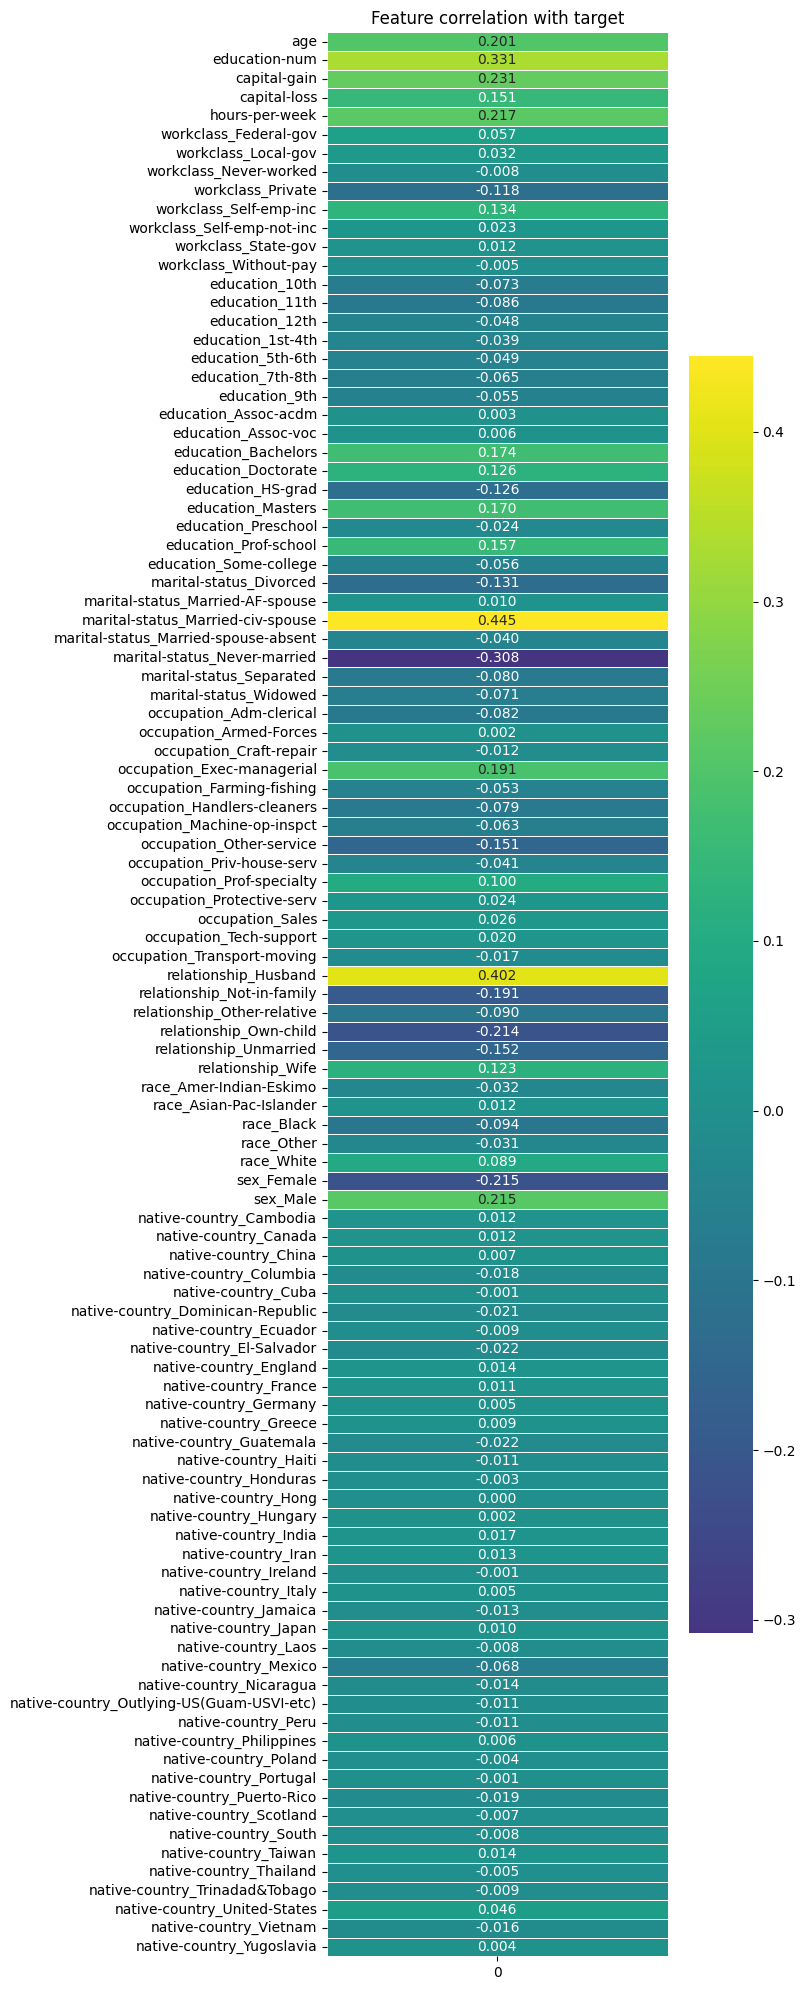

In [70]:
# Feature correlation with target

corr = X_train_final.corrwith(y_train_enc).to_frame()

plt.figure(figsize=(8, 20))
sns.heatmap(
    corr,
    annot=True,
    cmap="viridis",
    fmt=".3f",
    linewidths=0.5,
    center=0
)

plt.title("Feature correlation with target")
plt.tight_layout()
plt.show()

In [71]:
features_selected = ["hours-per-week","education-num", "marital-status_Married-civ-spouse"]

X_train_selected = X_train_smote[features_selected]
X_test_selected = X_test_final[features_selected]

In [72]:
X_train_selected.head()

,hours-per-week,education-num,marital-status_Married-civ-spouse
0,1.159547,-0.412807,0.0
1,0.757138,-0.412807,0.0
2,-1.657313,-0.412807,0.0
3,1.159547,-0.034063,1.0
4,-0.047679,1.102170,0.0
